# CSCN8000 – Lab 2: Probability, Naive Bayes and Outlier Detection
**Student:** Zeynep Ozdemir  |  **Student ID:** 9045142
**Date:** 23-10-2026
 
**Objectives:** Compare GaussianNB and MultinomialNB for spam detection;
examine NYC Airbnb prices and create several cleaned datasets.


## Importing Required Libraries

I imported the required Python libraries for data preprocessing, visualization, machine learning, and model evaluation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.preprocessing import MinMaxScaler
 
sns.set_theme(style="whitegrid")
DATA = Path("data")
print("CSV files:", [x.name for x in DATA.glob("*.csv")])


CSV files: ['AB_NYC_2019.csv', 'lab2_spam.csv']


# Part A — load and inspect the spam data

I loaded the spam dataset and checked its shape, columns, and missing values by using basic eda. I selected the `label` and `text` columns and renamed `text` to `message`.

I standardized the labels by removing extra spaces and converting them to lowercase. Finally, I converted the labels into numerical values, where ham = 0 and spam = 1, to prepare the dataset for machine learning.

In [7]:
SPAM_FILE = DATA / "lab2_spam.csv"  # CHANGE THIS
spam_df = pd.read_csv(SPAM_FILE, encoding="latin-1")
print("Shape:", spam_df.shape)
print("Columns:", spam_df.columns.tolist())
display(spam_df.head())
print(spam_df.isna().sum())


# Select the correct columns
LABEL_COL = "label"
TEXT_COL = "text"

# Create a copy of the required columns
work = spam_df[[LABEL_COL, TEXT_COL]].copy()
work.columns = ["label", "message"]

# Remove missing values
work = work.dropna(subset=["label", "message"])

# Convert messages to strings
work["message"] = work["message"].astype(str)

# Clean the labels
work["label"] = work["label"].astype(str).str.strip().str.lower()

# Count spam and ham messages
print("Labels:", work["label"].value_counts())

# Check that there are exactly two classes
assert work["label"].nunique() == 2, "Expected 2 classes"

# Convert labels to numerical values
if set(work["label"].unique()) == {"spam", "ham"}:
    work["target"] = work["label"].map({"ham": 0, "spam": 1})
else:
    raise ValueError("Check your label values")

# Display the cleaned dataset
display(work.head())


Shape: (5171, 4)
Columns: ['Unnamed: 0', 'label', 'text', 'label_num']


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64
Labels: label
ham     3672
spam    1499
Name: count, dtype: int64


,label,message,target
0,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\nthis deal is to ...,0


# Part A — split, vectorize, train, evaluate

In this task, I split the data into 80% training and 20% testing. I used CountVectorizer to convert text into numerical values because machine learning algorithms work with numerical patterns to train and make predictions. After training GaussianNB and MultinomialNB, I evaluated both models using accuracy, precision, recall, F1-score, and confusion matrices. GaussianNB achieved 95% accuracy, while MultinomialNB achieved 98% accuracy. Therefore, I selected MultinomialNB because it had the highest accuracy.

,model,accuracy,precision_spam,recall_spam,f1_spam
1,MultinomialNB,0.9758,0.9693,0.9467,0.9578
0,GaussianNB,0.9546,0.9408,0.9000,0.9199


GaussianNB report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97       735
           1       0.94      0.90      0.92       300

    accuracy                           0.95      1035
   macro avg       0.95      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035

MultinomialNB report:
               precision    recall  f1-score   support

           0       0.98      0.99      0.98       735
           1       0.97      0.95      0.96       300

    accuracy                           0.98      1035
   macro avg       0.97      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



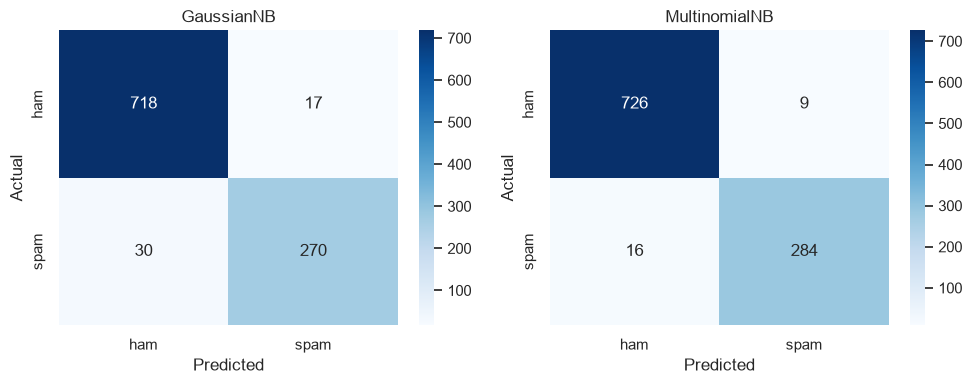

Best model by spam F1-score: MultinomialNB


,message,actual,gaussian_pred,multinomial_pred
294,Subject: account activated\nthank you for repl...,0,0,0
453,Subject: canvas\n2005 cable t v de 5 rambler w...,1,1,1
638,Subject: re : brandywine meter # : 981225 ; ma...,0,0,0
139,Subject: issues\nvalero has accepted this prop...,0,0,0
539,Subject: union carbide - safety net gas\nunion...,0,0,0
365,Subject: re : april spot tickets\nthe spot dea...,0,0,0
513,Subject: re : big cowboy for august\nmary :\ni...,0,0,0
584,"Subject: enron nominations for november 8 , 20...",0,0,0
231,Subject: re : txu fuel deals imbalances\ni ' m...,0,0,0
210,Subject: nesa / hea ' s 9 th annual crawfish b...,0,0,0


In [9]:
# Step 1: Split the dataset (80% training, 20% testing)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    work["message"],
    work["target"],
    test_size=0.20,
    random_state=42,
    stratify=work["target"]
)

# Step 2: Convert text into word counts
vectorizer = CountVectorizer(stop_words="english")
X_train_counts = vectorizer.fit_transform(X_train_text)
X_test_counts = vectorizer.transform(X_test_text)

# Step 3: Train MultinomialNB
multi = MultinomialNB()
multi.fit(X_train_counts, y_train)
pred_multi = multi.predict(X_test_counts)

# Step 4: Train GaussianNB
# GaussianNB requires dense arrays
X_train_dense = X_train_counts.toarray()
X_test_dense = X_test_counts.toarray()

gauss = GaussianNB()
gauss.fit(X_train_dense, y_train)
pred_gauss = gauss.predict(X_test_dense)

# Step 5: Evaluate both models
def score_row(name, actual, predicted):
    return {
        "model": name,
        "accuracy": accuracy_score(actual, predicted),
        "precision_spam": precision_score(actual, predicted, zero_division=0),
        "recall_spam": recall_score(actual, predicted, zero_division=0),
        "f1_spam": f1_score(actual, predicted, zero_division=0)
    }

results = pd.DataFrame([
    score_row("GaussianNB", y_test, pred_gauss),
    score_row("MultinomialNB", y_test, pred_multi)
]).sort_values("f1_spam", ascending=False)

display(results.round(4))

# Step 6: Classification reports
print("GaussianNB report:\n", classification_report(y_test, pred_gauss))
print("MultinomialNB report:\n", classification_report(y_test, pred_multi))

# Step 7: Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, preds in zip(
    axes,
    ["GaussianNB", "MultinomialNB"],
    [pred_gauss, pred_multi]
):
    cm = confusion_matrix(y_test, preds, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"]
    )

    ax.set(title=name, xlabel="Predicted", ylabel="Actual")

plt.tight_layout()
plt.show()

# Step 8: Find the best model
best_name = results.iloc[0]["model"]
print("Best model by spam F1-score:", best_name)

# Step 9: Display sample predictions
predictions = pd.DataFrame({
    "message": X_test_text.to_numpy(),
    "actual": y_test.to_numpy(),
    "gaussian_pred": pred_gauss,
    "multinomial_pred": pred_multi
})

display(predictions.sample(min(10, len(predictions)), random_state=42))

# Part A — use the trained model for new predictions

I entered new text to make predictions using the trained model

In [12]:
examples = [
    "Congratulations Zeynep! Claim your free cash prize now",
    "Hi Professor, are we still meeting at 3 pm today?",
    "URGENT: click this link to verify your account"
]
examples_counts = vectorizer.transform(examples)
chosen_predictions = (multi.predict(examples_counts)
                      if best_name == "MultinomialNB"
                      else gauss.predict(examples_counts.toarray()))
for text, label in zip(examples, chosen_predictions):
    print(f"{'spam' if label == 1 else 'ham'}: {text}")


spam: Congratulations Zeynep! Claim your free cash prize now
ham: Hi Professor, are we still meeting at 3 pm today?
spam: URGENT: click this link to verify your account
